# Shepp-Logan analysis

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from finsler_learning.shepplogan_pipeline.aggregate_shepplogan_results import (
    METHODS,
    BASE_METHODS,
    collect_base_geometry_metrics,
    collect_base_geometry_quality,
    merge_base_geometry_table,
    base_latex_table,
    collect_biased_extrapolation,
    merge_biased_extrapolation_table,
    biased_extrapolation_latex_table,
)

sns.set_context("notebook")
plt.rcParams["figure.figsize"] = (10, 6)

/home/tblanchard/phd/finsler_learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
base_path = Path("/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11")

## Base setup: recovered data

In [3]:
df_inter, df_extra = collect_base_geometry_metrics(base_path, BASE_METHODS)
df_quality_inter, df_quality_extra = collect_base_geometry_quality(base_path, BASE_METHODS)
df_inter

Interpolation metrics missing for Wasserstein, Finsler=False: [Errno 2] No such file or directory: '/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11/geodesic_evaluation_wasserstein/geo_kendall_tau_list_test.pth'
Interpolation metrics missing for Wasserstein, Finsler=True: [Errno 2] No such file or directory: '/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11/geodesic_evaluation_wasserstein_randers/geo_kendall_tau_list_test.pth'
Extrapolation metrics missing for Wasserstein, Finsler=True: [Errno 2] No such file or directory: '/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11/extrapolation_evaluation_wasserstein_randers/extrapolation_kendall_tau_test.pth'
Interpolation metrics missing for HyperSpherical, Finsler=True: [Errno 2] No such file or directory: '/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11/geodesic_evaluation_spherical_randers/geo_kendall_tau_list_test.pth'
Extrapolation metrics mi

,Geodesic Distance,Kendall Tau,Base Metric,Finsler
0,6.337707,1.0,Euclidean,False
1,5.636283,1.0,Euclidean,False
2,8.033120,1.0,Euclidean,False
3,5.346326,1.0,Euclidean,False
4,9.225510,1.0,Euclidean,False
...,...,...,...,...
2745,1.134804,1.0,HyperSpherical,False
2746,0.919400,1.0,HyperSpherical,False
2747,0.620878,1.0,HyperSpherical,False
2748,1.445359,1.0,HyperSpherical,False


## Interpolation

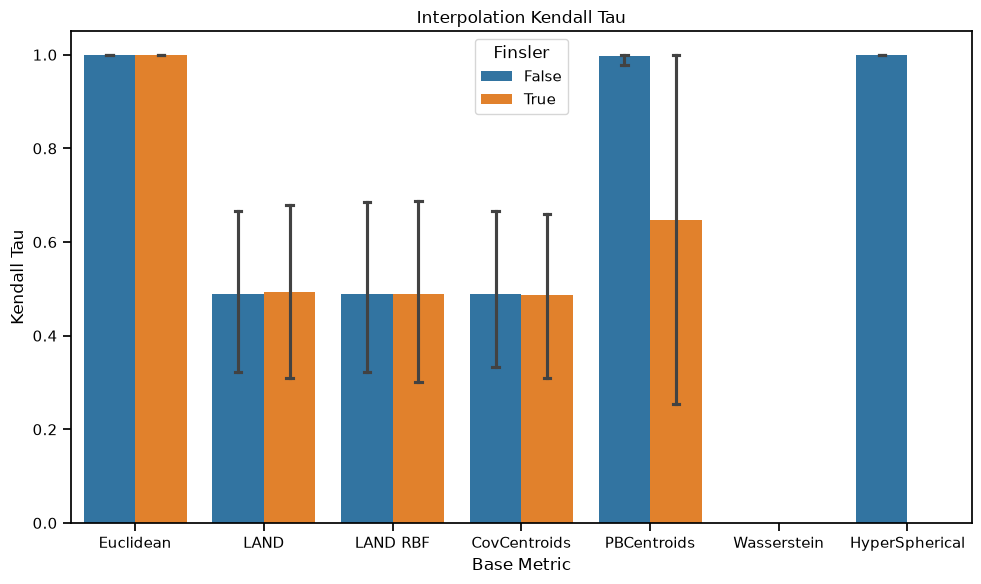

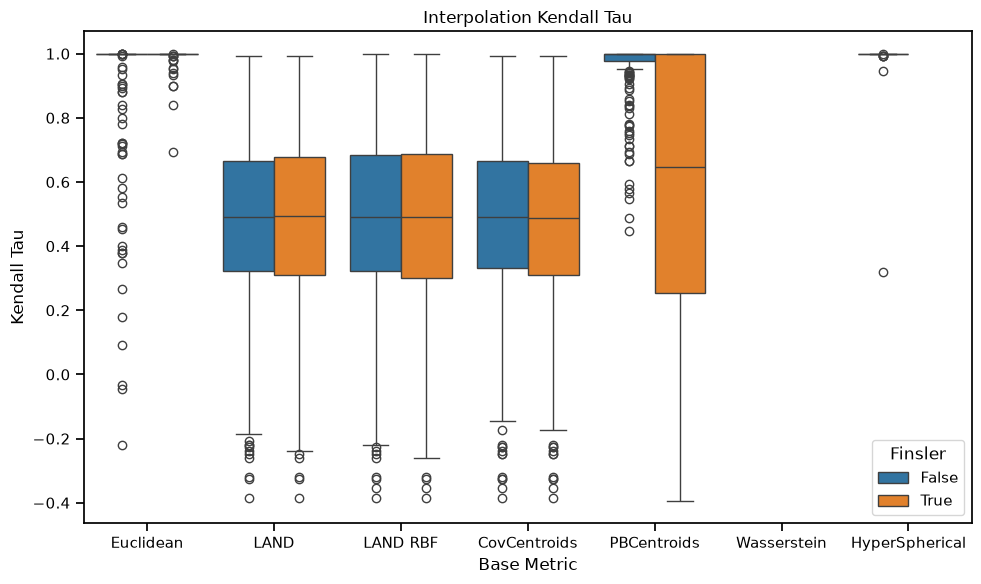

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(
    data=df_inter,
    x="Base Metric",
    y="Kendall Tau",
    hue="Finsler",
    order=[name for name, _ in BASE_METHODS],
    estimator="median",
    errorbar=("pi", 50),
    capsize=0.1,
    ax=ax,
)
ax.set_title("Interpolation Kendall Tau")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.boxplot(
    data=df_inter,
    x="Base Metric",
    y="Kendall Tau",
    hue="Finsler",
    order=[name for name, _ in BASE_METHODS],
    ax=ax,
)
ax.set_title("Interpolation Kendall Tau")
plt.tight_layout()
plt.show()

## Extrapolation

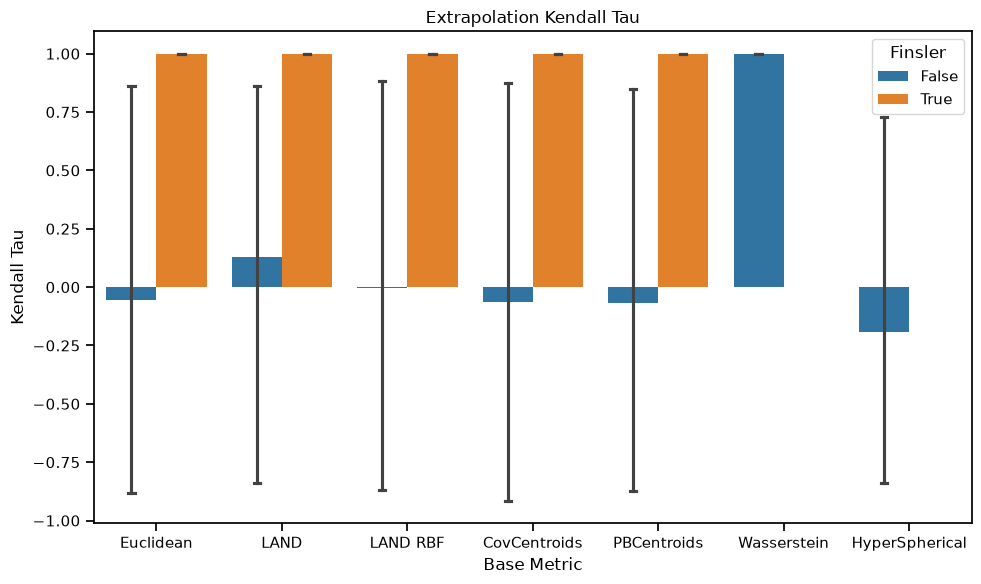

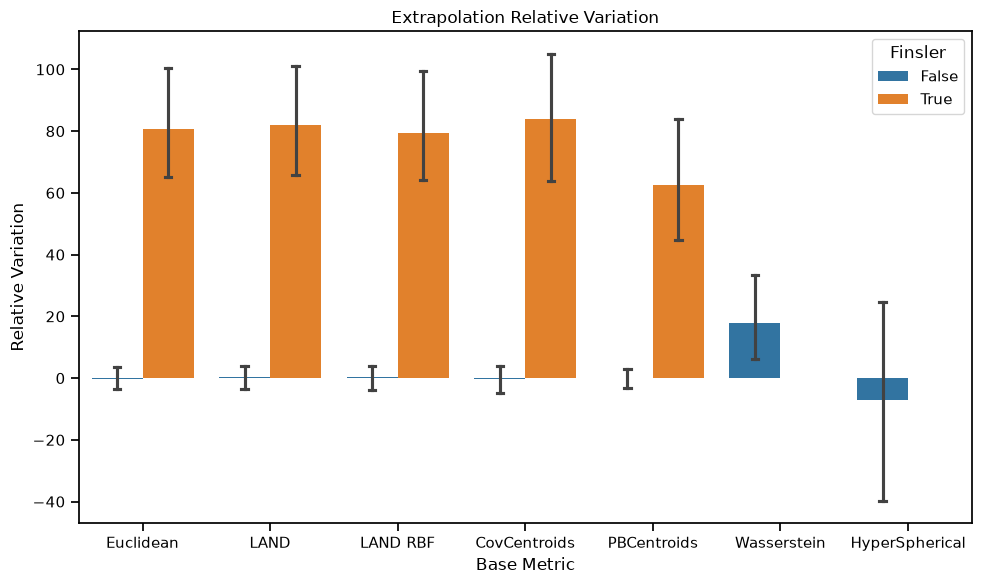

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(
    data=df_extra,
    x="Base Metric",
    y="Kendall Tau",
    hue="Finsler",
    order=[name for name, _ in BASE_METHODS],
    estimator="median",
    errorbar=("pi", 50),
    capsize=0.1,
    ax=ax,
)
ax.set_title("Extrapolation Kendall Tau")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(
    data=df_extra,
    x="Base Metric",
    y="Relative Variation",
    hue="Finsler",
    order=[name for name, _ in BASE_METHODS],
    estimator="median",
    errorbar=("pi", 50),
    capsize=0.1,
    ax=ax,
)
ax.set_title("Extrapolation Relative Variation")
plt.tight_layout()
plt.show()

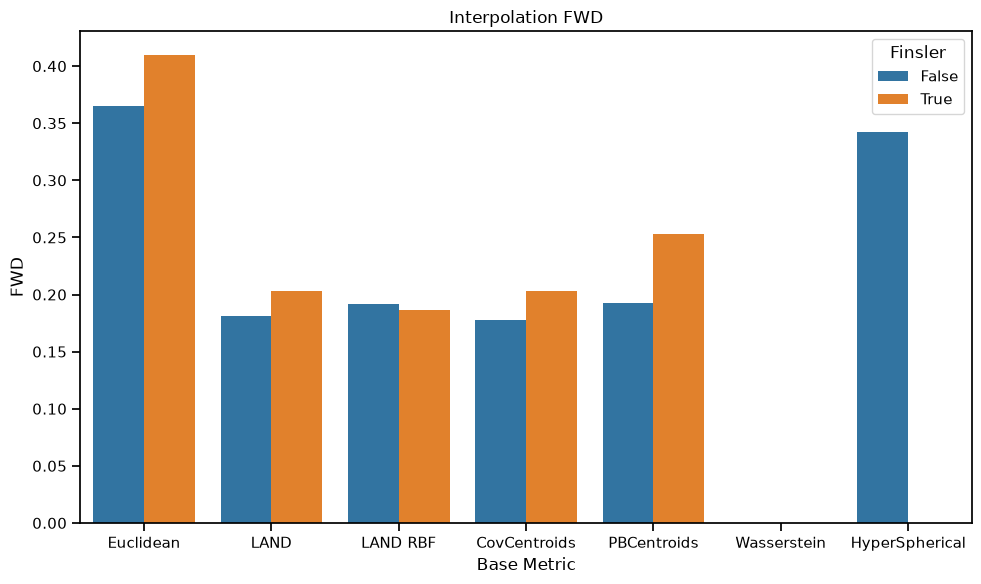

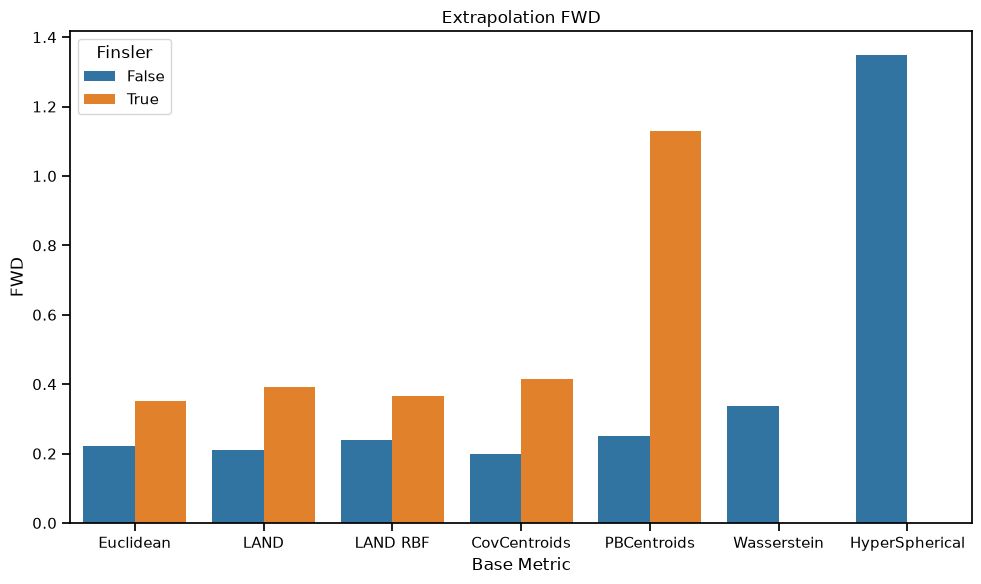

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(
    data=df_quality_inter,
    x="Base Metric",
    y="FWD",
    hue="Finsler",
    order=[name for name, _ in BASE_METHODS],
    ax=ax,
    errorbar=None,
)
ax.set_title("Interpolation FWD")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(
    data=df_quality_extra,
    x="Base Metric",
    y="FWD",
    hue="Finsler",
    order=[name for name, _ in BASE_METHODS],
    ax=ax,
    errorbar=None,
)
ax.set_title("Extrapolation FWD")
plt.tight_layout()
plt.show()

## Base combined results

In [7]:
combined = merge_base_geometry_table(
    df_inter,
    df_extra,
    df_quality_inter,
    df_quality_extra,
)
combined

,Base Metric,Finsler,Kendall Tau Median Inter,Kendall Tau IQR Inter,Kendall Tau Median Extra,Kendall Tau IQR Extra,Relative Variation Median Extra,Relative Variation IQR Extra,FWD Inter,FWD Extra
0,CovCentroids,False,0.490000,"(0.33333333333333326, 0.6666666666666665)",-0.061803,"(-0.9145791763183047, 0.8748036080825928)",-0.265130,"(-4.964807510375977, 4.041528224945068)",0.177679,0.199618
1,CovCentroids,True,0.486667,"(0.30999999999999994, 0.6599999999999998)",1.000000,"(0.9999999999999998, 0.9999999999999998)",83.840446,"(63.840091705322266, 105.08301544189453)",0.203050,0.415531
2,Euclidean,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",-0.054078,"(-0.8840648287704509, 0.863354767439195)",-0.196610,"(-3.5116692781448364, 3.5142588019371033)",0.365006,0.220615
3,Euclidean,True,1.000000,"(0.9999999999999998, 0.9999999999999998)",1.000000,"(0.9999999999999998, 0.9999999999999998)",80.795265,"(65.02141189575195, 100.50840950012207)",0.409939,0.352272
4,HyperSpherical,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",-0.193333,"(-0.8403944049049314, 0.7283333333333333)",-7.196951,"(-39.68564510345459, 24.777785778045654)",0.342504,1.349279
5,LAND,False,0.490000,"(0.32333333333333325, 0.6666666666666665)",0.129967,"(-0.8404484467817104, 0.8631348224244216)",0.366680,"(-3.5983189940452576, 3.7930848002433777)",0.181288,0.209896
6,LAND,True,0.493333,"(0.30999999999999994, 0.6783333333333332)",1.000000,"(0.9999999999999998, 0.9999999999999998)",81.973099,"(65.75410461425781, 101.1511173248291)",0.202665,0.391417
7,LAND RBF,False,0.490000,"(0.32166666666666655, 0.6849999999999998)",-0.003367,"(-0.8708276406707715, 0.8833455521376704)",0.227453,"(-3.7219122648239136, 3.7623250484466553)",0.191902,0.238577
8,LAND RBF,True,0.490000,"(0.3016666666666666, 0.6866666666666665)",1.000000,"(0.9999999999999998, 0.9999999999999998)",79.292862,"(64.0742359161377, 99.34869384765625)",0.186354,0.365346
9,PBCentroids,False,0.998332,"(0.9782985252259703, 0.9999999999999998)",-0.067703,"(-0.871453635098902, 0.8468901427586845)",-0.040638,"(-3.1611927151679993, 2.802289068698883)",0.192335,0.250417


In [8]:
caption = (
    r"Combined extrapolation and interpolation results on the Shepp-Logan dataset. "
    r"Here, $d=64, \alpha=5.0, \eta=0.999$, and $\zeta=0.9$. "
    r"Values are reported as median [IQR]."
)
latex = base_latex_table(
    combined,
    caption=caption,
    label="tab:combined_results_shepplogan",
    method_order=BASE_METHODS,
)
print(latex)

\begin{table}[ht]
\centering
\caption{Combined extrapolation and interpolation results on the Shepp-Logan dataset. Here, $d=64, \alpha=5.0, \eta=0.999$, and $\zeta=0.9$. Values are reported as median [IQR].}
\label{tab:combined_results_shepplogan}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccccc}
\toprule
    & & \multicolumn{2}{c}{Interpolation} & \multicolumn{3}{c}{Extrapolation} \\
    \cmidrule(lr){3-4} \cmidrule(lr){5-7}
    Base metric & Finsler
      & Kendall Tau ($\uparrow$) & FWD ($\downarrow$)
      & Kendall Tau ($\uparrow$) & Relative Variation (\%) & FWD ($\downarrow$) \\
\midrule
    \multirow{2}{*}{Euclidean} & \xmark & $1.00\,[1.00, 1.00]$ & $0.37$ & $-0.05\,[-0.88, 0.86]$ & $-0.20\,[-3.51, 3.51]$ & $0.22$ \\
     & \checkmark & $1.00\,[1.00, 1.00]$ & $0.41$ & $1.00\,[1.00, 1.00]$ & $80.80\,[65.02, 100.51]$ & $0.35$ \\
\midrule
    \multirow{2}{*}{LAND} & \xmark & $0.49\,[0.32, 0.67]$ & $0.18$ & $0.13\,[-0.84, 0.86]$ & $0.37\,[-3.60, 3.79]$ & $0.21$ \\
     & \check

## Raw extrapolation scatter plots

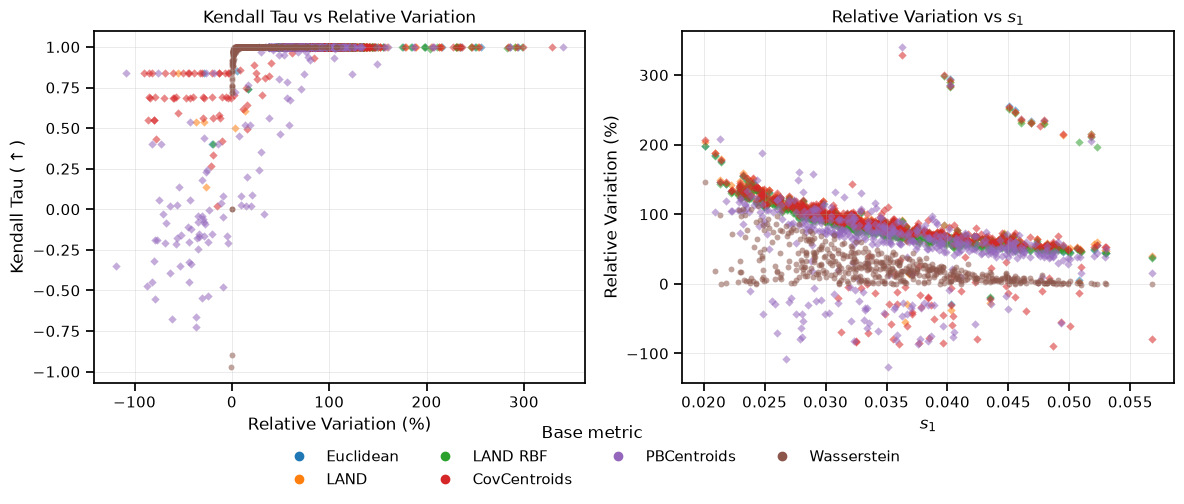

In [9]:
import pandas as pd
from matplotlib.lines import Line2D

plot_data = df_extra.loc[
    (df_extra["Finsler"] == True) | (df_extra["Base Metric"] == "Wasserstein")
].copy()

method_names = [name for name, _ in BASE_METHODS]
plot_data["Base Metric"] = pd.Categorical(
    plot_data["Base Metric"], categories=method_names, ordered=True
)
plot_data = plot_data.sort_values("Base Metric")

palette = dict(zip(method_names, sns.color_palette("tab10", len(method_names))))
markers = {False: "o", True: "D"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

for _, row in plot_data.iterrows():
    name = str(row["Base Metric"])
    color = palette.get(name, "0.50")
    marker = markers[bool(row["Finsler"])]

    ax1.scatter(
        row["Relative Variation"],
        row["Kendall Tau"],
        s=18,
        c=[color],
        marker=marker,
        alpha=0.55,
        linewidths=0,
    )
    ax2.scatter(
        row["First Time"],
        row["Relative Variation"],
        s=18,
        c=[color],
        marker=marker,
        alpha=0.55,
        linewidths=0,
    )

ax1.set_title("Kendall Tau vs Relative Variation")
ax1.set_xlabel("Relative Variation (%)")
ax1.set_ylabel(r"Kendall Tau ($\uparrow$)")
ax1.grid(True, linewidth=0.5, alpha=0.35)

ax2.set_title(r"Relative Variation vs $s_1$")
ax2.set_xlabel(r"$s_1$")
ax2.set_ylabel("Relative Variation (%)")
ax2.grid(True, linewidth=0.5, alpha=0.35)

handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        color=palette[name],
        markerfacecolor=palette[name],
        markersize=6,
        label=name,
    )
    for name in method_names
    if name in plot_data["Base Metric"].astype(str).values
]
if handles:
    fig.legend(
        handles=handles,
        title="Base metric",
        loc="lower center",
        ncol=min(4, len(handles)),
        frameon=False,
        bbox_to_anchor=(0.5, -0.02),
    )

fig.tight_layout(rect=(0, 0.08, 1, 1))
# fig.savefig(
#     "/home/tblanchard/phd/finsler_learning/src/finsler_learning/shepplogan_pipeline/s1_vs_rest_shepplogan.pdf",
#     dpi=300,
#     bbox_inches="tight",
# )
plt.show()

## Kendall Tau versus FWD

In [10]:
from matplotlib.lines import Line2D


def plot_base_tau_vs_fwd(combined, method_order=BASE_METHODS, save_path=None):
    combined = combined.copy()
    combined["Finsler"] = combined["Finsler"].astype(bool)

    method_names = [name for name, _ in method_order]
    combined["Base Metric"] = pd.Categorical(
        combined["Base Metric"], categories=method_names, ordered=True
    )
    combined = combined.sort_values(["Base Metric", "Finsler"])

    colors = dict(zip(method_names, sns.color_palette("tab10", len(method_names))))
    shapes = ["o", "s", "^", "v", "D", "P", "X", "<", ">", "h", "*", "p"]
    markers = {name: shapes[index % len(shapes)] for index, name in enumerate(method_names)}

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
    panels = [
        ("Interpolation", "FWD Inter", "Kendall Tau Median Inter", "Kendall Tau IQR Inter"),
        ("Extrapolation", "FWD Extra", "Kendall Tau Median Extra", "Kendall Tau IQR Extra"),
    ]

    for ax, (title, fwd_column, tau_column, iqr_column) in zip(axes, panels):
        for _, row in combined.iterrows():
            x = pd.to_numeric(pd.Series([row[fwd_column]]), errors="coerce").iloc[0]
            y = pd.to_numeric(pd.Series([row[tau_column]]), errors="coerce").iloc[0]
            iqr = row[iqr_column]
            if pd.isna(x) or pd.isna(y) or not isinstance(iqr, tuple):
                continue

            low, high = iqr
            low = float(low)
            high = float(high)
            name = str(row["Base Metric"])
            color = colors.get(name, "0.50")

            ax.errorbar(
                x,
                y,
                yerr=[[max(0.0, y - low)], [max(0.0, high - y)]],
                fmt="none",
                ecolor=color,
                elinewidth=1.2,
                capsize=3,
                capthick=1.2,
                alpha=0.8,
                zorder=2,
            )
            ax.scatter(
                x,
                y,
                s=55,
                marker=markers.get(name, "o"),
                facecolor=color if bool(row["Finsler"]) else "white",
                edgecolor=color,
                linewidth=1.5,
                zorder=3,
            )

        ax.set_title(title)
        ax.set_xlabel(r"FWD ($\downarrow$)")
        ax.set_ylim(-1.1, 1.1)
        ax.grid(True, linewidth=0.5, alpha=0.35)

    axes[0].set_ylabel(r"Kendall Tau ($\uparrow$)")

    metric_handles = [
        Line2D([], [], marker=markers[name], linestyle="", color=colors[name], label=name)
        for name in method_names
        if name in combined["Base Metric"].astype(str).values
    ]
    variant_handles = [
        Line2D(
            [],
            [],
            marker="o",
            linestyle="",
            markerfacecolor="grey",
            markeredgecolor="grey",
            label="Finsler",
        ),
        Line2D(
            [],
            [],
            marker="o",
            linestyle="",
            markerfacecolor="white",
            markeredgecolor="grey",
            label="Base",
        ),
    ]

    leg1 = fig.legend(
        handles=metric_handles,
        title="Base metric",
        loc="center left",
        bbox_to_anchor=(1.0, 0.62),
        frameon=False,
    )
    fig.legend(
        handles=variant_handles,
        title="Variant",
        loc="center left",
        bbox_to_anchor=(1.0, 0.18),
        frameon=False,
    )
    fig.add_artist(leg1)

    fig.tight_layout(rect=(0, 0, 0.86, 1))
    if save_path:
        fig.savefig(save_path, bbox_inches="tight", dpi=300)
    return fig, axes

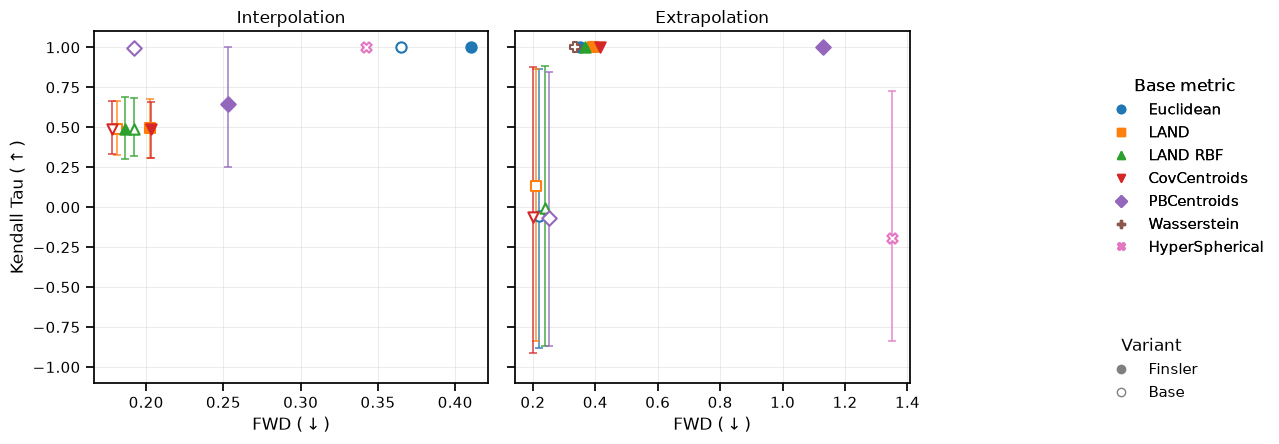

In [11]:
fig, axes = plot_base_tau_vs_fwd(
    combined,
    method_order=BASE_METHODS,
    # save_path="/home/tblanchard/phd/finsler_learning/src/finsler_learning/shepplogan_pipeline/scatter_plot_shepplogan.pdf",
    save_path=None,
)
plt.show()

## Biased extrapolation comparison

In [12]:
biased_extra, biased_quality = collect_biased_extrapolation(
    base_path,
    methods=METHODS,
)
biased_combined = merge_biased_extrapolation_table(
    biased_extra,
    biased_quality,
)
biased_combined

,Base Metric,Finsler,Biased,Kendall Tau Median Extra,Kendall Tau IQR Extra,Relative Variation Median Extra,Relative Variation IQR Extra,FWD Extra
0,CovCentroids,False,True,1.000000,"(0.9999999999999998, 0.9999999999999998)",78.669128,"(62.356773376464844, 98.44255065917969)",0.367099
1,CovCentroids,True,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",83.840446,"(63.840091705322266, 105.08301544189453)",0.415531
2,Euclidean,False,True,1.000000,"(0.9999999999999998, 0.9999999999999998)",80.421967,"(65.03569412231445, 100.25620460510254)",0.351308
3,Euclidean,True,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",80.795265,"(65.02141189575195, 100.50840950012207)",0.352272
4,LAND,False,True,1.000000,"(0.9999999999999998, 0.9999999999999998)",78.528831,"(63.410865783691406, 98.28654479980469)",0.352470
5,LAND,True,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",81.973099,"(65.75410461425781, 101.1511173248291)",0.391417
6,LAND RBF,False,True,1.000000,"(0.9999999999999998, 0.9999999999999998)",78.918228,"(63.77409648895264, 98.39956092834473)",0.378680
7,LAND RBF,True,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",79.292862,"(64.0742359161377, 99.34869384765625)",0.365346
8,PBCentroids,False,True,0.853333,"(0.39534822430787825, 0.9866666666666666)",26.841757,"(11.553135395050049, 44.4061222076416)",0.337709
9,PBCentroids,True,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",62.699211,"(44.647377014160156, 83.97538375854492)",1.128548


In [13]:
biased_caption = (
    r"Extrapolation results on the Shepp-Logan dataset, comparing the Finsler metric "
    r"to a biased Riemannian sampling rule baseline. "
    r"Here, $d=64, \alpha=5.0, \eta=0.999$, and $\zeta=0.9$. "
    r"Values are reported as median [IQR]."
)
biased_latex = biased_extrapolation_latex_table(
    biased_combined,
    caption=biased_caption,
    label="tab:riemannian_guided_shepplogan",
    method_order=METHODS,
)
print(biased_latex)

\begin{table}[ht]
\centering
\caption{Extrapolation results on the Shepp-Logan dataset, comparing the Finsler metric to a biased Riemannian sampling rule baseline. Here, $d=64, \alpha=5.0, \eta=0.999$, and $\zeta=0.9$. Values are reported as median [IQR].}
\label{tab:riemannian_guided_shepplogan}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llccc}
\toprule
    & & \multicolumn{3}{c}{Extrapolation} \\
    \cmidrule(lr){3-5}
    Base metric & Geometry
      & Kendall Tau ($\uparrow$) & Relative Variation (\%) & FWD ($\downarrow$) \\
\midrule
    \multirow{2}{*}{Euclidean} & Finsler & $1.00\,[1.00, 1.00]$ & $80.80\,[65.02, 100.51]$ & $0.35$ \\
     & Riemann (biased) & $1.00\,[1.00, 1.00]$ & $80.42\,[65.04, 100.26]$ & $0.35$ \\
\midrule
    \multirow{2}{*}{LAND} & Finsler & $1.00\,[1.00, 1.00]$ & $81.97\,[65.75, 101.15]$ & $0.39$ \\
     & Riemann (biased) & $1.00\,[1.00, 1.00]$ & $78.53\,[63.41, 98.29]$ & $0.35$ \\
\midrule
    \multirow{2}{*}{LAND RBF} & Finsler & $1.00\,[1.00, 1.00]$ & 